Enter filter size (3, 5, etc.):  3
Enter padding (zero/replicate):  replicate


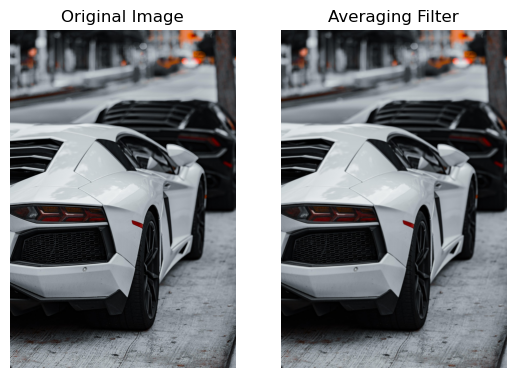

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("car.jpg")
n = int(input("Enter filter size (3, 5, etc.): "))
padding = input("Enter padding (zero/replicate): ")

if padding == "zero":
    border = cv2.BORDER_CONSTANT
else:
    border = cv2.BORDER_REPLICATE

kernel = np.ones((n, n), np.float32) / (n * n)
result = cv2.filter2D(
    image,
    -1,
    kernel,
    borderType=border
)

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Averaging Filter")
plt.axis("off")
plt.show()

Enter filter size (3, 5, etc.):  3
Enter padding (zero/replicate):  replicate


Weighted Filter:
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


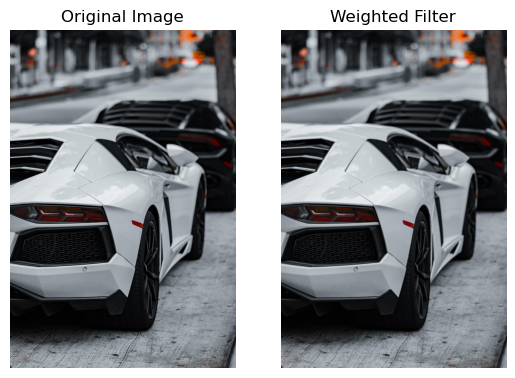

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("car.jpg")
n = int(input("Enter filter size (3, 5, etc.): "))
padding = input("Enter padding (zero/replicate): ")

if padding == "zero":
    border = cv2.BORDER_CONSTANT
else:
    border = cv2.BORDER_REPLICATE
kernel = np.zeros((n, n), dtype=np.float32)
center = n // 2

for i in range(n):
    for j in range(n):

        x = i - center
        y = j - center

        kernel[i, j] = max(abs(x), abs(y))
kernel[center, center] = 1
kernel = kernel / np.sum(kernel)

print("Weighted Filter:")
print(kernel)
result = cv2.filter2D(
    image,
    -1,
    kernel,
    borderType=border
)

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Weighted Filter")
plt.axis("off")
plt.show()

Enter filter size (3, 5, etc.):  3
Enter sigma:  1
Enter padding (zero/replicate):  replicate


Gaussian Kernel:
[[0.07511361 0.1238414  0.07511361]
 [0.1238414  0.20417996 0.1238414 ]
 [0.07511361 0.1238414  0.07511361]]


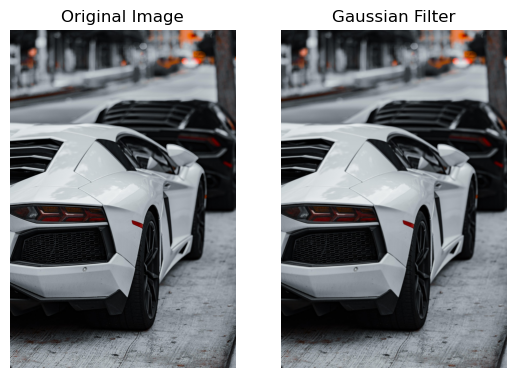

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("car.jpg")
if image is None:
    print("Image not found. Check the image filename/path.")
    exit()

n = int(input("Enter filter size (3, 5, etc.): "))
sigma = float(input("Enter sigma: "))
padding = input("Enter padding (zero/replicate): ")

if padding == "zero":
    border = cv2.BORDER_CONSTANT
else:
    border = cv2.BORDER_REPLICATE

kernel_1d = cv2.getGaussianKernel(n, sigma)
kernel = kernel_1d @ kernel_1d.T

print("Gaussian Kernel:")
print(kernel)
result = cv2.filter2D(
    image,
    -1,
    kernel,
    borderType=border
)
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Filter")
plt.axis("off")
plt.show()